# Trabalho Prático Individual — Tópicos de Big Data em Python

**Aluno:** Theo Mencalha — **Matrícula:** 202502193254

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

CAMINHO_ORIGINAL = "dados/vendas_bigdata_2026.csv"
CAMINHO_TRATADO = "dados/vendas_tratadas.csv"

## 1. Inspeção inicial

In [2]:
df_raw = pd.read_csv(CAMINHO_ORIGINAL)
df_raw.head()

,pedido_id,data,cliente_id,categoria,produto,regiao,canal,forma_pagamento,quantidade,preco_unitario,desconto_percentual,valor,frete,avaliacao,devolvido
0,PED001179,2026-07-22,CLI0271,Games,Joystick,Norte,App,Cartão de crédito,1,437.67,10,393.90,0.00,NaN,Não
1,PED000866,2026-09-01,CLI0132,Eletrônicos,Headset,Sudeste,App,Pix,2,208.55,5,396.25,0.00,NaN,Não
2,PED000102,2026-09-15,CLI0198,Eletrônicos,Webcam,Norte,Site,Pix,4,298.89,5,1135.78,0.00,NaN,Não
3,PED000440,2026-05-13,CLI0244,Games,Joystick,NaN,App,Pix,2,388.42,0,776.84,0.00,3.3,Não
4,PED000059,2026-05-30,CLI0140,Casa,Ventilador,Sudeste,App,Cartão de crédito,1,222.85,0,222.85,27.58,NaN,Não


In [3]:
print("shape:", df_raw.shape)
df_raw.info()

shape: (1200, 15)
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   pedido_id            1200 non-null   str    
 1   data                 1199 non-null   str    
 2   cliente_id           1200 non-null   str    
 3   categoria            1192 non-null   str    
 4   produto              1200 non-null   str    
 5   regiao               1188 non-null   str    
 6   canal                1200 non-null   str    
 7   forma_pagamento      1200 non-null   str    
 8   quantidade           1200 non-null   int64  
 9   preco_unitario       1200 non-null   float64
 10  desconto_percentual  1200 non-null   int64  
 11  valor                1200 non-null   float64
 12  frete                1200 non-null   float64
 13  avaliacao            854 non-null    float64
 14  devolvido            1200 non-null   str    
dtypes: float64(4), int64(2), str(9)

In [4]:
print(df_raw.dtypes)
print("\nValores ausentes por coluna:")
print(df_raw.isna().sum())
print("\nLinhas duplicadas (linha inteira):", df_raw.duplicated().sum())
print("pedido_id repetidos:", df_raw["pedido_id"].duplicated().sum())

pedido_id                  str
data                       str
cliente_id                 str
categoria                  str
produto                    str
regiao                     str
canal                      str
forma_pagamento            str
quantidade               int64
preco_unitario         float64
desconto_percentual      int64
valor                  float64
frete                  float64
avaliacao              float64
devolvido                  str
dtype: object

Valores ausentes por coluna:
pedido_id                0
data                     1
cliente_id               0
categoria                8
produto                  0
regiao                  12
canal                    0
forma_pagamento          0
quantidade               0
preco_unitario           0
desconto_percentual      0
valor                    0
frete                    0
avaliacao              346
devolvido                0
dtype: int64

Linhas duplicadas (linha inteira): 8
pedido_id repetidos: 8


### Respostas

**Quantos registros existem?** 1.200 registros e 15 colunas.

**Problemas de qualidade identificados**:
- **8 linhas duplicadas**.
- **Datas inválidas/ausentes:** 1 data nula e 4 textos que não são datas válidas (`2026-02-30`, `31/11/2026`, `2026-13-05`, `data_invalida`). A coluna `data` vem como texto.
- **`regiao` com 12 nulos e palavres escritas de forma inconsistentes** (` Sudeste`, `sudeste`, `CENTRO-OESTE`, espaços extras etc.).
- **`categoria` com 8 nulos**.
- **`avaliacao` com 346 nulos** (~29%): clientes que não avaliaram.
- **`quantidade` ≤ 0** (5 linhas) e **`preco_unitario` ≤ 0** (5 linhas).
- **`valor` incoerente** com `quantidade × preco × (1 − desconto/100)` em 19 linhas.

**Primários ou secundários?** São dados secundários: foram coletados e registrados por terceiros (o sistema de vendas da empresa) para finalidade operacional e apenas *cedidos* a mim para análise; eu não os coletei nem controlei o processo de coleta.

## 2. Preparação e qualidade dos dados

Estratégia: trabalhar sobre uma cópia (`.copy()`), tratar cada problema em uma etapa, nunca apagar silenciosamente: registros inválidos vão para uma tabela de quarentena e as decisões são justificadas em cada etapa.

### 2.1 Conversão e validação da coluna de data

In [5]:
df = df_raw.copy()
df["data_original"] = df["data"]
df["data"] = pd.to_datetime(df["data_original"], format="%Y-%m-%d", errors="coerce")

datas_invalidas = df.loc[df["data"].isna(), ["pedido_id", "data_original"]]
print("Datas inválidas ou ausentes:", len(datas_invalidas))
datas_invalidas

Datas inválidas ou ausentes: 5


,pedido_id,data_original
237,PED000543,NaN
417,PED000669,2026-02-30
470,PED000772,31/11/2026
713,PED000808,data_invalida
1110,PED000379,2026-13-05


**Decisão:** `errors="coerce"` transforma o que não é data em `NaT`, e o valor original fica guardado em `data_original` para auditoria.

### 2.2 Duplicatas

In [6]:
colunas_originais = df_raw.columns.tolist()
dups = df.loc[df.duplicated(subset=colunas_originais, keep=False)].sort_values("pedido_id")
print("Linhas envolvidas em duplicação:", len(dups))
print("Duplicatas exatas a remover:", df.duplicated(subset=colunas_originais).sum())
print("pedido_id repetido com conteúdo diferente:",
      (df["pedido_id"].duplicated(keep=False) & ~df.duplicated(subset=colunas_originais, keep=False)).sum())
dups.head(4)

Linhas envolvidas em duplicação: 16
Duplicatas exatas a remover: 8
pedido_id repetido com conteúdo diferente: 0


,pedido_id,data,cliente_id,categoria,produto,regiao,canal,forma_pagamento,quantidade,preco_unitario,desconto_percentual,valor,frete,avaliacao,devolvido,data_original
4,PED000059,2026-05-30,CLI0140,Casa,Ventilador,Sudeste,App,Cartão de crédito,1,222.85,0,222.85,27.58,NaN,Não,2026-05-30
863,PED000059,2026-05-30,CLI0140,Casa,Ventilador,Sudeste,App,Cartão de crédito,1,222.85,0,222.85,27.58,NaN,Não,2026-05-30
61,PED000156,2026-09-07,CLI0273,Games,Joystick,Sul,Site,Cartão de crédito,1,470.95,0,470.95,0.00,NaN,Não,2026-09-07
513,PED000156,2026-09-07,CLI0273,Games,Joystick,Sul,Site,Cartão de crédito,1,470.95,0,470.95,0.00,NaN,Não,2026-09-07


In [7]:
df = df.drop_duplicates(subset=colunas_originais, keep="first").copy()
print("Registros após remover duplicatas:", len(df))

Registros após remover duplicatas: 1192


**Decisão:** as 8 duplicatas são cópias idênticas (mesmo `pedido_id`, mesmos valores) e nenhum `pedido_id` se repete com conteúdo diferente. Um pedido não pode existir duas vezes, e manter inflaria o faturamento; removi mantendo a primeira ocorrência.

### 2.3 Padronização da coluna `regiao`

In [8]:
print("Antes:", sorted(df["regiao"].dropna().unique()))
df["regiao"] = df["regiao"].str.strip().str.title()
print("Depois:", sorted(df["regiao"].dropna().unique()))

Antes: [' Nordeste ', ' Norte ', ' Sudeste ', ' Sul ', 'CENTRO-OESTE', 'Centro-Oeste', 'NORDESTE', 'Nordeste', 'Norte', 'SUDESTE', 'Sudeste', 'Sul', 'centro-oeste', 'nordeste', 'sudeste', 'sul']
Depois: ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']


**Decisão:** `strip()` remove espaços e `title()` unifica a caixa.

### 2.4 Valores ausentes

In [9]:
print("Ausentes antes:\n", df[["data", "categoria", "regiao", "avaliacao"]].isna().sum())

# categoria: cada produto pertence a uma única categoria -> dá para recuperar com segurança
print("\nMax. de categorias por produto:", df.groupby("produto")["categoria"].nunique().max())
mapa_categoria = df.dropna(subset=["categoria"]).drop_duplicates("produto").set_index("produto")["categoria"]
mascara_cat = df["categoria"].isna()
df.loc[mascara_cat, "categoria"] = df.loc[mascara_cat, "produto"].map(mapa_categoria)

# regiao: não há como inferir -> rótulo explícito, sem descartar a venda
df.loc[df["regiao"].isna(), "regiao"] = "Não informado"

print("\nAusentes depois:\n", df[["data", "categoria", "regiao", "avaliacao"]].isna().sum())

Ausentes antes:
 data           5
categoria      8
regiao        12
avaliacao    343
dtype: int64

Max. de categorias por produto: 1

Ausentes depois:
 data           5
categoria      0
regiao         0
avaliacao    343
dtype: int64


**Decisões:**
- `categoria`: imputada pelo produto, pois a relação produto → categoria é 1:1 no próprio dataset (sem chute).
- `regiao`: sem fonte para inferir; usei "Não informado" para não perder o faturamento e deixar a lacuna visível.
- `data`: mantida como `NaT` (seção 2.1).
- `avaliacao`: mantida nula. A ausência significa "cliente não avaliou" e a coluna não entra nas análises de faturamento; imputar média distorceria a nota real.

### 2.5 Quantidade ≤ 0, preço ≤ 0 e coerência do `valor`

In [10]:
df["valor_esperado"] = (
    df["quantidade"]
    * df["preco_unitario"]
    * (1 - df["desconto_percentual"] / 100)
).round(2)
df["diferenca_valor"] = (df["valor"] - df["valor_esperado"]).round(2)

TOLERANCIA = 0.02  # arredondamento de centavos

df["qtd_invalida"] = df["quantidade"] <= 0
df["preco_invalido"] = df["preco_unitario"] <= 0
df["valor_incoerente"] = df["diferenca_valor"].abs() > TOLERANCIA
df["registro_invalido"] = df[["qtd_invalida", "preco_invalido", "valor_incoerente"]].any(axis=1)

print("quantidade <= 0      :", df["qtd_invalida"].sum())
print("preco_unitario <= 0  :", df["preco_invalido"].sum())
print("valor incoerente     :", df["valor_incoerente"].sum())
print("registros inválidos  :", df["registro_invalido"].sum(), "(união dos três critérios)")

colunas_diag = ["pedido_id", "quantidade", "preco_unitario", "desconto_percentual", "valor", "valor_esperado", "diferenca_valor"]
df.loc[df["registro_invalido"], colunas_diag].sort_values("diferenca_valor")

quantidade <= 0      : 5
preco_unitario <= 0  : 5
valor incoerente     : 19
registros inválidos  : 19 (união dos três critérios)


,pedido_id,quantidade,preco_unitario,desconto_percentual,valor,valor_esperado,diferenca_valor
907,PED001129,4,280.22,10,504.39,1008.79,-504.40
997,PED000298,3,255.60,10,345.06,690.12,-345.06
756,PED000086,2,193.71,0,193.71,387.42,-193.71
878,PED001174,1,184.16,15,78.27,156.54,-78.27
324,PED001120,1,84.39,5,120.25,80.17,40.08
575,PED000134,0,82.23,15,69.90,0.00,69.90
1001,PED000946,1,94.57,15,160.76,80.38,80.38
42,PED001109,1,171.52,5,244.41,162.94,81.47
1101,PED001057,0,145.50,15,123.67,0.00,123.67
10,PED000821,2,301.83,0,905.49,603.66,301.83


**Decisão:** todos os registros com quantidade ≤ 0, preço ≤ 0 ou `valor` fora do esperado (tolerância de R$ 0,02 por arredondamento) são isolados em quarentena e excluídos das análises financeiras. Observações:
- Os 10 casos de quantidade/preço inválidos também violam a regra de negócio.
- Alguns casos parecem recuperáveis (ex.: preço negativo cujo `valor` bate com |preço|), mas não tem como saber qual campo está errado; corrigir seria adivinhar.

In [11]:
df_quarentena = df.loc[df["registro_invalido"]].copy()
df_clean = df.loc[~df["registro_invalido"]].copy()

# Fluxo de registros
print("Originais              :", len(df_raw))
print("(-) duplicatas         :", len(df_raw) - len(df))
print("(-) quarentena         :", len(df_quarentena))
print("= base analítica       :", len(df_clean))
print("   dos quais sem data  :", df_clean["data"].isna().sum())

Originais              : 1200
(-) duplicatas         : 8
(-) quarentena         : 19
= base analítica       : 1173
   dos quais sem data  : 5


In [12]:
# Salva a base tratada (insumo do PySpark). Colunas auxiliares de diagnóstico ficam de fora.
colunas_saida = colunas_originais + ["valor_esperado"]
df_clean[colunas_saida].to_csv(CAMINHO_TRATADO, index=False)
print("Base tratada salva em", CAMINHO_TRATADO, "->", df_clean.shape)

Base tratada salva em dados/vendas_tratadas.csv -> (1173, 22)


## 3. Análise com Pandas

**Definição:** *faturamento* = soma de `valor` (já líquido do desconto, sem frete), sobre a base tratada (`df_clean`).

In [13]:
fat_regiao = df_clean.groupby("regiao")["valor"].sum().sort_values(ascending=False)
print("1) Faturamento por região:")
print(fat_regiao.round(2))
print("\n=> Maior faturamento:", fat_regiao.idxmax(), f"(R$ {fat_regiao.max():,.2f} | {fat_regiao.max()/fat_regiao.sum():.1%} do total)")

1) Faturamento por região:
regiao
Sudeste          221696.45
Sul              111577.22
Nordeste         109187.76
Centro-Oeste      48972.60
Norte             37322.92
Não informado      6204.91
Name: valor, dtype: float64

=> Maior faturamento: Sudeste (R$ 221,696.45 | 41.4% do total)


In [14]:
top5_produtos = df_clean.groupby("produto")["valor"].sum().nlargest(5)
print("2) Top 5 produtos por faturamento:")
print(top5_produtos.round(2))

2) Top 5 produtos por faturamento:
produto
Cadeira      59544.32
Mesa         56813.67
Aspirador    41924.48
SSD 1TB      41869.38
Joystick     34735.11
Name: valor, dtype: float64


In [15]:
fat_canal = df_clean.groupby("canal")["valor"].sum().sort_values(ascending=False)
print("3) Faturamento por canal:")
print(fat_canal.round(2))
print("\n=> Maior faturamento:", fat_canal.idxmax(), f"({fat_canal.max()/fat_canal.sum():.1%} do total)")

3) Faturamento por canal:
canal
Site           271058.26
App            188191.72
Loja física     75711.88
Name: valor, dtype: float64

=> Maior faturamento: Site (50.7% do total)


In [16]:
pagamentos = df_clean["forma_pagamento"].value_counts()
print("4) Forma de pagamento (nº de pedidos):")
print(pagamentos)
print("\n=> Mais utilizada:", pagamentos.idxmax(), f"({pagamentos.max()/pagamentos.sum():.1%} dos pedidos)")

4) Forma de pagamento (nº de pedidos):
forma_pagamento
Pix                  487
Cartão de crédito    452
Cartão de débito     122
Boleto               112
Name: count, dtype: int64

=> Mais utilizada: Pix (41.5% dos pedidos)


In [17]:
# Evolução mensal (linhas sem data válida não entram)
df_mes = df_clean.dropna(subset=["data"]).copy()
df_mes["mes"] = df_mes["data"].dt.to_period("M")
mensal = df_mes.groupby("mes")["valor"].sum()
mensal_df = mensal.to_frame("faturamento")
mensal_df["var_mensal_%"] = (mensal_df["faturamento"].pct_change() * 100).round(1)
print("5) Faturamento mensal:")
print(mensal_df.round(2))
print("\nÚltima data na base:", df_mes["data"].max().date(), "-> novembro/2026 é um mês incompleto")

5) Faturamento mensal:
         faturamento  var_mensal_%
mes                               
2026-01     49056.09           NaN
2026-02     47292.85          -3.6
2026-03     52689.17          11.4
2026-04     48925.86          -7.1
2026-05     54810.54          12.0
2026-06     40499.81         -26.1
2026-07     67486.90          66.6
2026-08     48821.57         -27.7
2026-09     59631.44          22.1
2026-10     62000.09           4.0
2026-11      2378.18         -96.2

Última data na base: 2026-11-01 -> novembro/2026 é um mês incompleto


### Gráficos

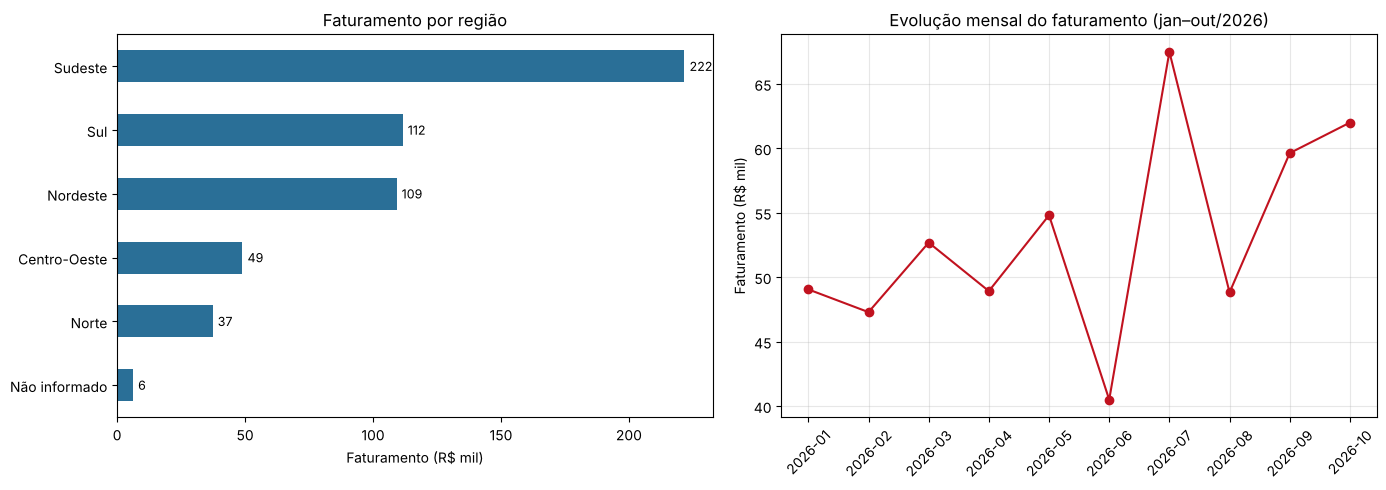

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: faturamento por região
(fat_regiao / 1000).sort_values().plot.barh(ax=axes[0], color="#2a6f97")
axes[0].set_title("Faturamento por região")
axes[0].set_xlabel("Faturamento (R$ mil)")
axes[0].set_ylabel("")
for i, v in enumerate((fat_regiao / 1000).sort_values()):
    axes[0].text(v + 2, i, f"{v:,.0f}", va="center", fontsize=9)

# Gráfico 2: evolução mensal (exclui nov/2026, mês incompleto)
mensal_completo = mensal[mensal.index < pd.Period("2026-11")]
axes[1].plot(mensal_completo.index.astype(str), mensal_completo.values / 1000, marker="o", color="#c1121f")
axes[1].set_title("Evolução mensal do faturamento (jan–out/2026)")
axes[1].set_ylabel("Faturamento (R$ mil)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusão

O faturamento bruto tratado soma cerca de R$ 535 mil em 1.173 pedidos válidos. O Sudeste lidera com R$ 221,7 mil (~41% do total), mais que o dobro do segundo colocado (Sul, R$ 111,6 mil). O Site é o canal dominante, com R$ 271 mil (~51%), à frente do App (R$ 188 mil) e da Loja física (R$ 76 mil). Cadeira e Mesa são os produtos que mais faturam (R$ 59,5 mil e R$ 56,8 mil), e o Pix é a forma de pagamento mais usada (~42% dos pedidos). Mês a mês não há tendência clara de crescimento: o faturamento oscila entre R$ 47 mil e R$ 55 mil até maio, cai em junho (R$ 40,5 mil) e atinge o pico em julho (R$ 67,5 mil); outubro (R$ 62 mil) também é forte. Cerca de 6% dos pedidos foram devolvidos (~R$ 34 mil), um custo a considerar. Recomenda-se investigar o que causou o pico de julho e a queda de junho, a baixa participação do Norte (R$ 37 mil), e corrigir na origem os problemas de qualidade (datas, região e valores).

## 4. PySpark DataFrame

In [19]:
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder
    .appName("trabalho_bigdata")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")   # base pequena: poucas partições
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

df_spark = spark.read.csv(CAMINHO_TRATADO, header=True, inferSchema=True)
df_spark.printSchema()
print("Registros no Spark:", df_spark.count())

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/16 22:36:23 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/16 22:36:23 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/16 22:36:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- pedido_id: string (nullable = true)
 |-- data: date (nullable = true)
 |-- cliente_id: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- produto: string (nullable = true)
 |-- regiao: string (nullable = true)
 |-- canal: string (nullable = true)
 |-- forma_pagamento: string (nullable = true)
 |-- quantidade: integer (nullable = true)
 |-- preco_unitario: double (nullable = true)
 |-- desconto_percentual: integer (nullable = true)
 |-- valor: double (nullable = true)
 |-- frete: double (nullable = true)
 |-- avaliacao: double (nullable = true)
 |-- devolvido: string (nullable = true)
 |-- valor_esperado: double (nullable = true)



Registros no Spark: 1173


In [20]:
resumo_regioes = (
    df_spark
    .filter((F.col("quantidade") > 0) & (F.col("preco_unitario") > 0))   # transformação
    .groupBy("regiao")                                                   # transformação (wide)
    .agg(                                                                # transformação
        F.round(F.sum("valor"), 2).alias("faturamento_total"),
        F.countDistinct("pedido_id").alias("qtd_pedidos"),
        F.sum("quantidade").alias("qtd_itens"),
    )
    .orderBy(F.col("faturamento_total").desc())                          # transformação (wide)
)

resumo_regioes.show()   # AÇÃO: dispara a execução

+-------------+-----------------+-----------+---------+
|       regiao|faturamento_total|qtd_pedidos|qtd_itens|
+-------------+-----------------+-----------+---------+
|      Sudeste|        221696.45|        509|      969|
|          Sul|        111577.22|        230|      458|
|     Nordeste|        109187.76|        230|      453|
| Centro-Oeste|          48972.6|        110|      215|
|        Norte|         37322.92|         83|      160|
|Não informado|          6204.91|         11|       23|
+-------------+-----------------+-----------+---------+



In [21]:
# Plano físico: observe o "Exchange hashpartitioning(regiao...)" = shuffle do groupBy
resumo_regioes.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [faturamento_total#54 DESC NULLS LAST], true, 0
   +- Exchange rangepartitioning(faturamento_total#54 DESC NULLS LAST, 4), ENSURE_REQUIREMENTS, [plan_id=206]
      +- HashAggregate(keys=[regiao#22], functions=[sum(valor#28), sum(quantidade#25), count(distinct pedido_id#17)])
         +- Exchange hashpartitioning(regiao#22, 4), ENSURE_REQUIREMENTS, [plan_id=203]
            +- HashAggregate(keys=[regiao#22], functions=[merge_sum(valor#28), merge_sum(quantidade#25), partial_count(distinct pedido_id#17)])
               +- HashAggregate(keys=[regiao#22, pedido_id#17], functions=[merge_sum(valor#28), merge_sum(quantidade#25)])
                  +- Exchange hashpartitioning(regiao#22, pedido_id#17, 4), ENSURE_REQUIREMENTS, [plan_id=199]
                     +- HashAggregate(keys=[regiao#22, pedido_id#17], functions=[partial_sum(valor#28), partial_sum(quantidade#25)])
                        +- Project [pedido_id#17, regiao#22, 

In [22]:
# Exporta o resultado (toPandas também é uma ação) e valida contra o Pandas
resumo_pd = resumo_regioes.toPandas()
resumo_pd.to_csv("resultado/resumo_regioes.csv", index=False)

conferencia = df_clean.groupby("regiao")["valor"].sum().round(2)
assert (resumo_pd.set_index("regiao")["faturamento_total"].sort_index() - conferencia.sort_index()).abs().max() < 0.01
print("Spark e Pandas conferem. Arquivo salvo em resultado/resumo_regioes.csv")
resumo_pd

Spark e Pandas conferem. Arquivo salvo em resultado/resumo_regioes.csv


,regiao,faturamento_total,qtd_pedidos,qtd_itens
0,Sudeste,221696.45,509,969
1,Sul,111577.22,230,458
2,Nordeste,109187.76,230,453
3,Centro-Oeste,48972.60,110,215
4,Norte,37322.92,83,160
5,Não informado,6204.91,11,23


## 5. Spark SQL

In [23]:
df_spark.createOrReplaceTempView("vendas")

# Pergunta: quais categorias têm a maior taxa de devolução nas vendas online (Site e App)?
consulta = """
SELECT
    categoria,
    COUNT(*)                                                   AS total_pedidos,
    SUM(CASE WHEN devolvido = 'Sim' THEN 1 ELSE 0 END)         AS pedidos_devolvidos,
    ROUND(100.0 * SUM(CASE WHEN devolvido = 'Sim' THEN 1 ELSE 0 END) / COUNT(*), 2) AS taxa_devolucao_pct
FROM vendas
WHERE canal IN ('Site', 'App')
GROUP BY categoria
ORDER BY taxa_devolucao_pct DESC
"""
spark.sql(consulta).show()

+-----------+-------------+------------------+------------------+
|  categoria|total_pedidos|pedidos_devolvidos|taxa_devolucao_pct|
+-----------+-------------+------------------+------------------+
|Eletrônicos|          204|                16|              7.84|
|       Casa|          204|                14|              6.86|
| Escritório|          191|                11|              5.76|
|      Games|          198|                11|              5.56|
| Acessórios|          210|                 9|              4.29|
+-----------+-------------+------------------+------------------+



Esta consulta responde uma pergunta diferente da seção 4.

## 6. HDFS e escalabilidade

Com um arquivo de vários TB no HDFS (fator de replicação 3), o arquivo é dividido em blocos (ex.: 128 MB), cada um replicado em 3 DataNodes.

- **NameNode:** é o "mestre" que guarda apenas os **metadados** (namespace, quais blocos formam cada arquivo e em quais DataNodes estão); não armazena dados e coordena leituras/escritas.
- **DataNodes:** são os "trabalhadores" que **armazenam fisicamente os blocos** e os servem aos clientes, reportando ao NameNode a lista de blocos que possuem.
- **Falta de heartbeat:** os DataNodes enviam heartbeats periódicos; se param de chegar por um tempo, o NameNode marca o nó como morto e replica os blocos que ele guardava a partir das cópias restantes, restaurando o fator 3.
- **Por que a replicação ajuda:** cada bloco existe em 3 nós (em geral, em racks diferentes); se um nó ou rack falha, os dados continuam acessíveis em outras cópias (alta disponibilidade e tolerância a falhas) e leituras podem ser feitas na réplica mais próxima.

## 7. Auditoria de Machine Learning

```python
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
```

### Problema: **vazamento de dados (data leakage)**

O `StandardScaler` é ajustado (`fit`) em todo o conjunto `X` *antes* da divisão treino/teste. A média e o desvio-padrão usados na padronização incluem, portanto, informação das linhas de teste, que deveriam ser "desconhecidas" durante o treino. O resultado é uma avaliação otimista: o desempenho medido no teste não representa o desempenho real com dados novos.

### Correção
Dividir primeiro e ajustar o scaler somente no treino; o teste apenas é transformado com os parâmetros do treino. Usar `Pipeline` garante isso automaticamente (inclusive dentro de validação cruzada, em que o scaler é reajustado em cada fold).

In [24]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Dados sintéticos apenas para demonstrar que o código corrigido executa
X, y = make_classification(n_samples=500, n_features=10, random_state=42)

# 1) Divide ANTES de qualquer ajuste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2) Pipeline: o scaler é ajustado só com X_train; o teste só é transformado
modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])
modelo.fit(X_train, y_train)
print(f"Acurácia no teste: {modelo.score(X_test, y_test):.3f}")

# 3) Validação cruzada sem vazamento (scaler reajustado em cada fold)
scores = cross_val_score(modelo, X_train, y_train, cv=5)
print(f"CV (5 folds): {scores.mean():.3f} ± {scores.std():.3f}")

Acurácia no teste: 0.880
CV (5 folds): 0.885 ± 0.033


In [25]:
spark.stop()